# 02 — Statistical diagnostics and preliminary analysis

**Thesis:** *Crude Oil Volatility Regimes and Time-Varying Transition Probabilities: The Predictive Roles of Geopolitical Risk and Financial-Market Uncertainty*

This notebook investigates daily oil-return distributions, stationarity, serial dependence, and conditional heteroskedasticity before any volatility or regime model is estimated. **Training data (2000–2015) determine the primary diagnostic conclusions and prespecified lag checks.** Full-sample and later-period summaries are descriptive context only; no model specification is chosen using the 2020–2026 test period. The notebook reads only the processed files created in Notebook 01 and can run from the project root or the notebooks directory.

## 1. Verify processed inputs

The expected snapshot contains 6,495 maximum Brent returns, 6,410 complete-case Brent returns, and 6,336 complete-case WTI robustness returns. We halt on a count, date, split, missing-key, or duplicate-date discrepancy. Missing VIX fields in the maximum Brent file are allowed because that sample preserves all usable Brent returns; the complete-case files must have no missing fields. WTI statistics therefore describe the **saved complete-case robustness sample**, not the larger unsaved maximum WTI-return series in Notebook 01. Time-series lags below count retained observations rather than calendar days; weekends, holidays, and complete-case selection create unequal calendar gaps.

In [1]:
from pathlib import Path
import platform
import warnings

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
from scipy import stats
import statsmodels
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.tools.sm_exceptions import InterpolationWarning
from IPython.display import Markdown, display

PROJECT = Path.cwd() if (Path.cwd() / "data" / "processed").is_dir() else Path.cwd().parent
DATA = PROJECT / "data" / "processed"
TABLES = PROJECT / "results" / "tables"
FIGURES = PROJECT / "results" / "figures"
assert DATA.is_dir(), f"Processed data directory missing: {DATA}"
expected_counts = {"brent_max": 6495, "brent_complete_case": 6410, "wti_robustness": 6336}
expected_period = (pd.Timestamp("2000-01-04"), pd.Timestamp("2026-10-26"))
TRAIN_END = pd.Timestamp("2015-12-31")
VALIDATION_END = pd.Timestamp("2019-12-31")

def expected_split(dates):
    return np.select([dates.le(TRAIN_END), dates.le(VALIDATION_END)],
                     ["train", "validation"], default="test")

samples = {}
verification = []
for name, count in expected_counts.items():
    path = DATA / f"01_{name}.csv"
    if not path.exists():
        raise FileNotFoundError(path)
    frame = pd.read_csv(path, parse_dates=["date"])
    return_col = "wti_return_pct" if name == "wti_robustness" else "brent_return_pct"
    required = {"date", "split", return_col, "gpr_index", "vix_index",
                "gpr_lag1_calendar_day", "vix_lag1_observation"}
    if not required.issubset(frame.columns):
        raise ValueError(f"{name}: missing columns {required - set(frame.columns)}")
    if len(frame) != count:
        raise ValueError(f"{name}: expected {count} rows; found {len(frame)}. Stop and review Notebook 01.")
    if (frame["date"].min(), frame["date"].max()) != expected_period:
        raise ValueError(f"{name}: unexpected date range; review the input snapshot.")
    if frame["date"].isna().any() or frame["date"].duplicated().any() or not frame["date"].is_monotonic_increasing:
        raise ValueError(f"{name}: invalid, duplicate, or unsorted dates")
    if frame[["date", "split", return_col]].isna().any().any():
        raise ValueError(f"{name}: missing date, split, or return")
    if not frame["split"].eq(expected_split(frame["date"])).all():
        raise ValueError(f"{name}: split labels do not match the declared boundaries")
    if name != "brent_max" and frame.isna().any().any():
        raise ValueError(f"{name}: complete-case file has missing values")
    samples[name] = frame
    verification.append({"sample": name, "observations": len(frame),
                         "first_date": frame["date"].min().date(),
                         "last_date": frame["date"].max().date(),
                         "duplicate_dates": int(frame["date"].duplicated().sum()),
                         "missing_returns": int(frame[return_col].isna().sum()),
                         "missing_VIX": int(frame["vix_index"].isna().sum()),
                         "train": int(frame["split"].eq("train").sum()),
                         "validation": int(frame["split"].eq("validation").sum()),
                         "test": int(frame["split"].eq("test").sum())})

brent = samples["brent_max"]
complete = samples["brent_complete_case"]
wti = samples["wti_robustness"]
if not set(complete["date"]).issubset(set(brent["date"])):
    raise ValueError("Complete-case Brent dates are not contained in maximum Brent dates")
comparison = complete[["date", "brent_return_pct"]].merge(
    brent[["date", "brent_return_pct"]], on="date", suffixes=("_complete", "_max"),
    validate="one_to_one")
if not np.allclose(comparison["brent_return_pct_complete"],
                   comparison["brent_return_pct_max"], rtol=0, atol=1e-9):
    raise ValueError("Brent return values disagree between saved samples")
if wti["date"].isin(pd.to_datetime(["2020-04-20", "2020-04-21"])).any():
    raise ValueError("WTI sample unexpectedly contains a return affected by the negative price")
if len(brent) - len(complete) != brent["vix_index"].isna().sum():
    raise ValueError("Brent complete-case loss no longer matches missing same-day VIX")

reference_path = DATA / "01_sample_summary.csv"
if not reference_path.exists():
    raise FileNotFoundError(reference_path)
reference = pd.read_csv(reference_path).set_index("sample")
for row in verification:
    recorded = reference.loc[row["sample"]]
    for key in ["observations", "train", "validation", "test"]:
        if int(recorded[key]) != row[key]:
            raise ValueError(f"{row['sample']}: {key} differs from Notebook 01 sample summary")
    for key in ["first_date", "last_date"]:
        if str(recorded[key]) != str(row[key]):
            raise ValueError(f"{row['sample']}: {key} differs from Notebook 01 sample summary")

display(pd.DataFrame(verification))
display(pd.Series({"Python": platform.python_version(), "pandas": pd.__version__,
                   "NumPy": np.__version__, "SciPy": scipy.__version__,
                   "statsmodels": statsmodels.__version__,
                   "Matplotlib": matplotlib.__version__}, name="version").to_frame())
TABLES.mkdir(parents=True, exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)

,sample,observations,first_date,last_date,duplicate_dates,missing_returns,missing_VIX,train,validation,test
0,brent_max,6495,2000-01-04,2026-10-26,0,0,85,3750,1020,1725
1,brent_complete_case,6410,2000-01-04,2026-10-26,0,0,0,3699,999,1712
2,wti_robustness,6336,2000-01-04,2026-10-26,0,0,0,3633,1000,1703


,version
Python,3.12.14
pandas,3.0.1
NumPy,2.5.4
SciPy,1.18.1
statsmodels,0.15.0
Matplotlib,3.11.2


## 2. Descriptive statistics and return distributions

Returns are percentage log returns. The comparative table first uses each entire saved sample for historical description. The split table separately shows training, validation, and test periods; later periods are **not** used to choose diagnostic lags or model specifications. Histograms and normal Q-Q plots use **training observations only**. Their fitted normal curves have the training sample's mean and sample standard deviation, so tail departures are visible against a simple reference distribution. Q-Q departures are visual evidence, whereas the Jarque–Bera test below supplies a formal normality test.

Extreme valid returns remain in all tables and figures. In particular, the 2020 table is descriptive test-period context. Notebook 01 retained the negative WTI price on 20 April 2020 in its price audit and marked the 20 and 21 April log returns undefined; this notebook does not recreate them.

In [2]:
oil = {"Brent": (brent, "brent_return_pct"), "WTI": (wti, "wti_return_pct")}

def describe(series):
    q = series.quantile([.01, .99])
    return {"n": int(series.count()), "mean_pct": series.mean(), "median_pct": series.median(),
            "sd_pct": series.std(ddof=1), "min_pct": series.min(), "p01_pct": q.loc[.01],
            "p99_pct": q.loc[.99], "max_pct": series.max(), "skewness": series.skew(),
            "excess_kurtosis": series.kurt()}

full_descriptive = pd.DataFrame([
    {"oil": name, "scope": "full saved sample; descriptive", **describe(frame[col])}
    for name, (frame, col) in oil.items()
])
display(full_descriptive.round(3))
full_descriptive.to_csv(TABLES / "02_return_descriptive.csv", index=False, float_format="%.10g")

split_descriptive = pd.DataFrame([
    {"oil": name, "period": period, **describe(frame.loc[frame["split"].eq(period), col]),
     "abs_return_gt_10pct": int(frame.loc[frame["split"].eq(period), col].abs().gt(10).sum())}
    for name, (frame, col) in oil.items()
    for period in ["train", "validation", "test"]
])
display(split_descriptive.round(3))
split_descriptive.to_csv(TABLES / "02_split_descriptive.csv", index=False, float_format="%.10g")

extreme_2020 = pd.concat([
    frame.loc[frame["date"].dt.year.eq(2020), ["date", col]]
         .assign(oil=name, absolute_return_pct=lambda d: d[col].abs())
         .nlargest(5, "absolute_return_pct")
         .rename(columns={col: "return_pct"})[["oil", "date", "return_pct", "absolute_return_pct"]]
    for name, (frame, col) in oil.items()
], ignore_index=True)
display(extreme_2020)
extreme_2020.to_csv(TABLES / "02_2020_extreme_returns.csv", index=False,
                    date_format="%Y-%m-%d", float_format="%.10g")

,oil,scope,n,mean_pct,median_pct,sd_pct,min_pct,p01_pct,p99_pct,max_pct,skewness,excess_kurtosis
0,Brent,full saved sample; descriptive,6495,0.025,0.067,2.738,-64.370,-7.100,6.859,41.202,-1.726,64.158
1,WTI,full saved sample; descriptive,6336,0.033,0.121,2.848,-28.138,-7.592,7.178,42.583,0.308,24.085


,oil,period,n,mean_pct,median_pct,sd_pct,min_pct,p01_pct,p99_pct,max_pct,skewness,excess_kurtosis,abs_return_gt_10pct
0,Brent,train,3750,0.010,0.035,2.342,-19.891,-6.579,6.108,18.130,-0.339,5.986,17
1,Brent,validation,1020,0.060,0.091,2.168,-6.449,-5.124,6.197,11.070,0.347,2.302,1
2,Brent,test,1725,0.037,0.146,3.679,-64.370,-9.226,7.978,41.202,-2.539,71.255,24
3,WTI,train,3633,0.008,0.084,2.594,-23.263,-7.262,6.535,16.414,-0.513,7.133,23
4,WTI,validation,1000,0.051,0.131,2.265,-8.724,-5.839,6.311,14.176,0.327,3.673,3
5,WTI,test,1703,0.074,0.157,3.579,-28.138,-9.333,8.212,42.583,0.931,30.833,28


,oil,date,return_pct,absolute_return_pct
0,Brent,2020-04-21,-64.369891,64.369891
1,Brent,2020-04-22,41.202251,41.202251
2,Brent,2020-04-02,30.161265,30.161265
3,Brent,2020-03-31,-25.638944,25.638944
4,Brent,2020-03-09,-25.517526,25.517526
5,WTI,2020-04-22,42.583241,42.583241
6,WTI,2020-03-31,37.473777,37.473777
7,WTI,2020-03-09,-28.138208,28.138208
8,WTI,2020-03-18,-27.490549,27.490549
9,WTI,2020-04-27,-27.298962,27.298962


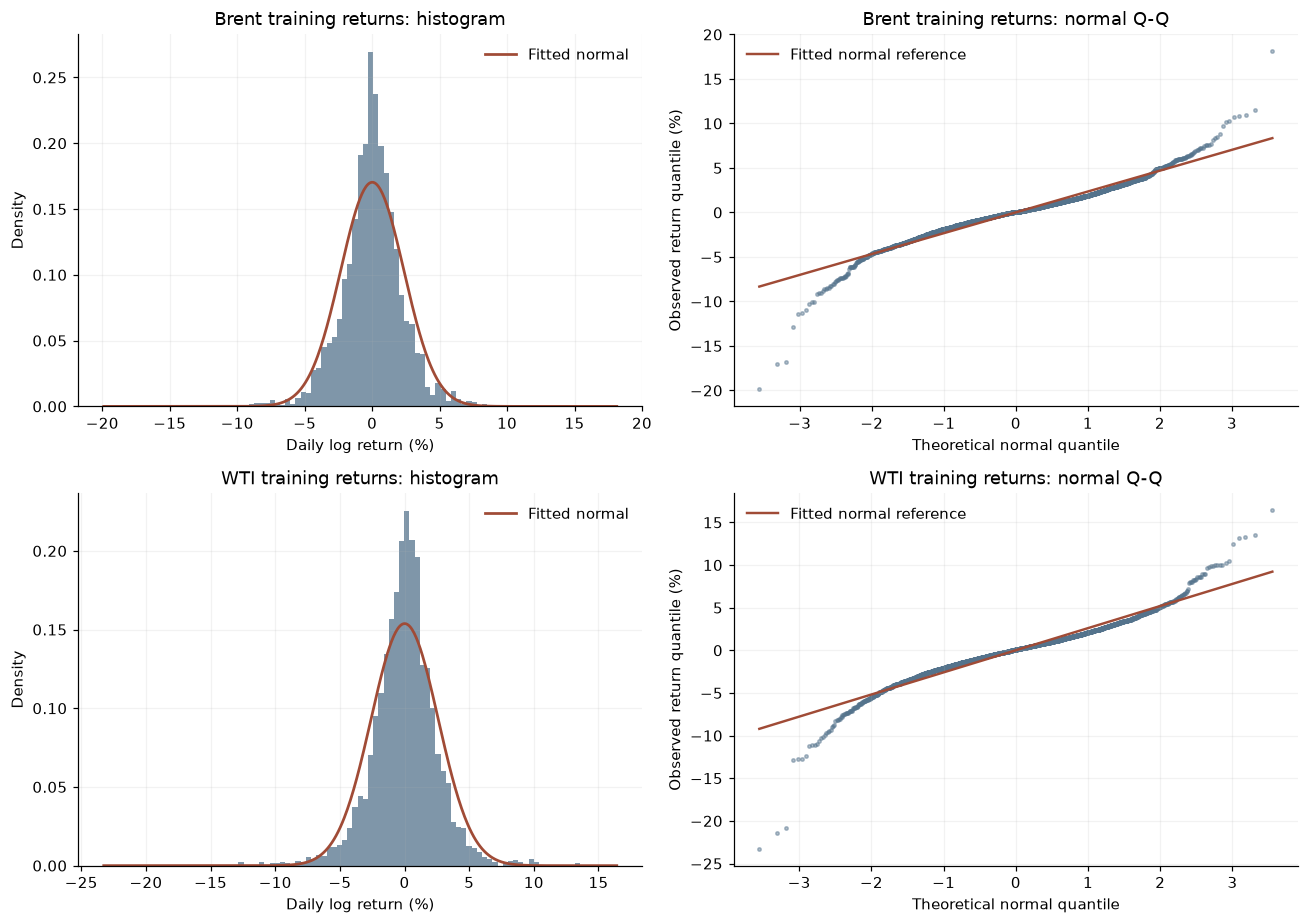

In [3]:
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 180, "font.size": 10,
                     "axes.spines.top": False, "axes.spines.right": False})
fig, axes = plt.subplots(2, 2, figsize=(12, 8.5))
for row, (name, (frame, col)) in enumerate(oil.items()):
    x = frame.loc[frame["split"].eq("train"), col].to_numpy()
    mu, sigma = x.mean(), x.std(ddof=1)
    bins = np.histogram_bin_edges(x, bins="fd")
    bins = np.linspace(x.min(), x.max(), min(len(bins), 100))
    axes[row, 0].hist(x, bins=bins, density=True, color="#54738c", alpha=.75)
    grid = np.linspace(x.min(), x.max(), 500)
    axes[row, 0].plot(grid, stats.norm.pdf(grid, mu, sigma), color="#a04b36",
                      lw=1.8, label="Fitted normal")
    axes[row, 0].set(title=f"{name} training returns: histogram",
                     xlabel="Daily log return (%)", ylabel="Density")
    axes[row, 0].legend(frameon=False)
    theoretical, ordered = stats.probplot(x, dist="norm", fit=False)
    axes[row, 1].scatter(theoretical, ordered, s=5, alpha=.45, color="#54738c")
    axes[row, 1].plot(theoretical, mu + sigma * np.asarray(theoretical),
                      color="#a04b36", lw=1.6, label="Fitted normal reference")
    axes[row, 1].set(title=f"{name} training returns: normal Q-Q",
                     xlabel="Theoretical normal quantile", ylabel="Observed return quantile (%)")
    axes[row, 1].legend(frameon=False)
for ax in axes.flat:
    ax.grid(alpha=.16)
fig.tight_layout()
fig.savefig(FIGURES / "02_return_distributions.png", bbox_inches="tight")
plt.show()

## 3. Stationarity: complementary ADF and KPSS tests

The ADF null is a **unit root**; the KPSS null is **level stationarity**. Using both offers complementary evidence, although neither is proof of a particular data-generating process. Daily returns are tested with an intercept and no deterministic time trend: a nonzero mean is possible, but a deterministic linear drift in returns is not imposed. ADF searches lags 0–20 by AIC; KPSS uses its automatic long-run variance lag rule. Both settings are specified before looking at the test-period data. We use 5% as the decision threshold and report the lag actually selected. KPSS p-values at 0.01 or 0.10 are table bounds, not exact tail probabilities. Structural breaks or volatility changes can affect unit-root tests. Implementation references: [ADF](https://www.statsmodels.org/stable/generated/statsmodels.tsa.stattools.adfuller.html) and [KPSS](https://www.statsmodels.org/stable/generated/statsmodels.tsa.stattools.kpss.html).

In [4]:
train = {name: frame.loc[frame["split"].eq("train"), col].to_numpy()
         for name, (frame, col) in oil.items()}

def formatted_p(p, test=""):
    if test == "KPSS" and p >= .10:
        return ">=0.10 (table bound)"
    if test == "KPSS" and p <= .01:
        return "<=0.01 (table bound)"
    if p == 0:
        return "<1e-300 (underflow)"
    return f"{p:.3g}"

stationarity_rows = []
summary_rows = []
for name, x in train.items():
    adf = adfuller(x, maxlag=20, regression="c", autolag="AIC", result_object=False)
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always")
        kp = kpss(x, regression="c", nlags="auto", result_object=False)
    if any(not issubclass(w.category, InterpolationWarning) for w in caught):
        raise RuntimeError(f"{name}: unexpected KPSS warning requires review")
    stationarity_rows.extend([
        {"oil": name, "test": "ADF", "null_hypothesis": "unit root",
         "test_statistic": adf[0], "p_value": adf[1], "p_display": formatted_p(adf[1]),
         "selected_lags": int(adf[2]), "effective_n": int(adf[3]),
         "specification": "intercept; AIC among lags 0-20",
         "interpretation": "Reject unit root" if adf[1] < .05 else "Do not reject unit root"},
        {"oil": name, "test": "KPSS", "null_hypothesis": "level stationarity",
         "test_statistic": kp[0], "p_value": kp[1], "p_display": formatted_p(kp[1], "KPSS"),
         "selected_lags": int(kp[2]), "effective_n": len(x),
         "specification": "intercept; automatic long-run variance lags",
         "interpretation": "Reject level stationarity" if kp[1] < .05
                           else "Do not reject level stationarity"},
    ])
stationarity = pd.DataFrame(stationarity_rows)
display(stationarity[["oil", "test", "null_hypothesis", "test_statistic",
                      "p_display", "selected_lags", "effective_n",
                      "specification", "interpretation"]].round(4))
stationarity.to_csv(TABLES / "02_stationarity.csv", index=False, float_format="%.10g")

,oil,test,null_hypothesis,test_statistic,p_display,selected_lags,effective_n,specification,interpretation
0,Brent,ADF,unit root,-60.0882,<1e-300 (underflow),0,3749,intercept; AIC among lags 0-20,Reject unit root
1,Brent,KPSS,level stationarity,0.3161,>=0.10 (table bound),7,3750,intercept; automatic long-run variance lags,Do not reject level stationarity
2,WTI,ADF,unit root,-16.2952,3.31e-29,12,3620,intercept; AIC among lags 0-20,Reject unit root
3,WTI,KPSS,level stationarity,0.2706,>=0.10 (table bound),17,3633,intercept; automatic long-run variance lags,Do not reject level stationarity


## 4. Autocorrelation in returns and squared returns

Autocorrelation of returns concerns linear dependence in their signed values. Autocorrelation of squared returns concerns persistence in **return magnitude**, a common signature of volatility clustering. The ACF plots show 30 observation lags with approximate white-noise 95% bands. Ljung–Box tests jointly assess zero autocorrelation through prespecified lags 5, 10, and 20. No mean or volatility model has been fitted, so no model degrees of freedom are subtracted. With thousands of observations, small return autocorrelations can be statistically significant; test significance should be read alongside ACF size. Implementation reference: [Ljung–Box](https://www.statsmodels.org/stable/generated/statsmodels.stats.diagnostic.acorr_ljungbox.html).

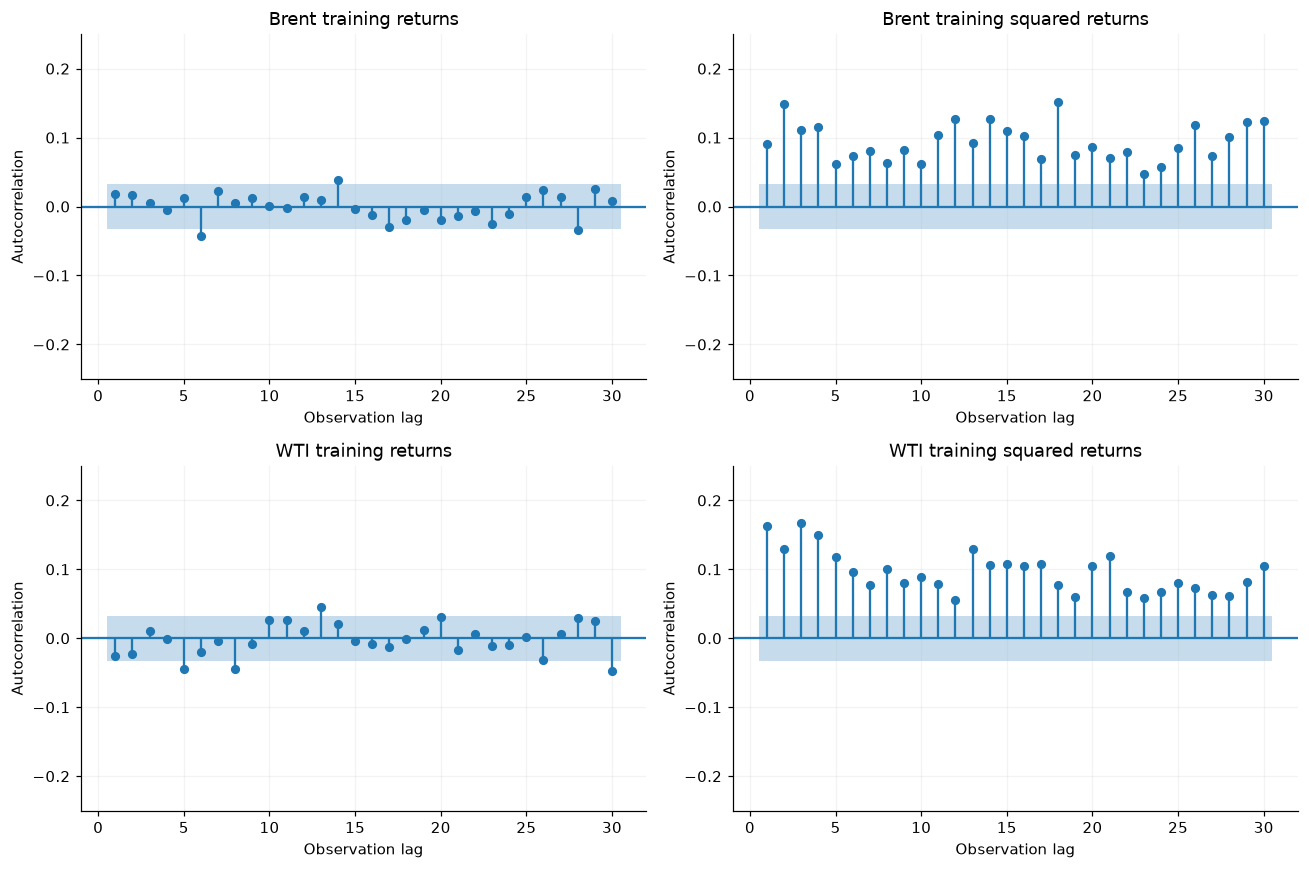

,oil,series,lags,test_statistic,p_value,p_display,interpretation
0,Brent,return,5,3.11383,0.68244,0.682,Do not reject no autocorrelation
1,Brent,return,10,12.52095,0.25170,0.252,Do not reject no autocorrelation
2,Brent,return,20,26.29191,0.15639,0.156,Do not reject no autocorrelation
3,Brent,squared return,5,224.26222,0.00000,1.81e-46,Reject no autocorrelation
4,Brent,squared return,10,323.94838,0.00000,1.33e-63,Reject no autocorrelation
5,Brent,squared return,20,755.62884,0.00000,3.66e-147,Reject no autocorrelation
6,WTI,return,5,12.17218,0.03250,0.0325,Reject no autocorrelation
7,WTI,return,10,23.62386,0.00866,0.00866,Reject no autocorrelation
8,WTI,return,20,40.38073,0.00447,0.00447,Reject no autocorrelation
9,WTI,squared return,5,391.84034,0.00000,1.7e-82,Reject no autocorrelation


In [5]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for row, (name, x) in enumerate(train.items()):
    plot_acf(x, lags=30, alpha=.05, zero=False, bartlett_confint=False,
             ax=axes[row, 0], title=f"{name} training returns")
    plot_acf(x ** 2, lags=30, alpha=.05, zero=False, bartlett_confint=False,
             ax=axes[row, 1], title=f"{name} training squared returns")
    for ax in axes[row]:
        ax.set(xlabel="Observation lag", ylabel="Autocorrelation", ylim=(-.25, .25))
        ax.grid(alpha=.15)
fig.tight_layout()
fig.savefig(FIGURES / "02_return_acf.png", bbox_inches="tight")
plt.show()

ljung_rows = []
for name, x in train.items():
    for transform, y in [("return", x), ("squared return", x ** 2)]:
        lb = acorr_ljungbox(y, lags=[5, 10, 20], model_df=0, return_df=True)
        for lag, result in lb.iterrows():
            ljung_rows.append({"oil": name, "series": transform, "lags": int(lag),
                               "test_statistic": result["lb_stat"], "p_value": result["lb_pvalue"],
                               "p_display": formatted_p(result["lb_pvalue"]),
                               "interpretation": "Reject no autocorrelation" if result["lb_pvalue"] < .05
                                                 else "Do not reject no autocorrelation"})
ljung = pd.DataFrame(ljung_rows)
display(ljung.round(5))
ljung.to_csv(TABLES / "02_ljung_box.csv", index=False, float_format="%.10g")

## 5. ARCH effects

Engle's ARCH-LM test asks whether squared, demeaned returns depend on their own past values. The null is **no ARCH effects through the chosen lag**. We use 10 lags as the primary prespecified specification and show 5 and 20 lags as sensitivity checks. Demeaning estimates one training-sample mean, so a one-degree-of-freedom adjustment is applied to the LM statistic. Significant results support time-varying conditional variance; they do not establish that any particular GARCH or regime model is correct. Implementation reference: [ARCH-LM](https://www.statsmodels.org/stable/generated/statsmodels.stats.diagnostic.het_arch.html).

In [6]:
arch_rows = []
for name, x in train.items():
    residual = x - x.mean()
    for lag in [5, 10, 20]:
        lm_stat, lm_p, f_stat, f_p = het_arch(
            residual, nlags=lag, ddof=1, result_object=False)
        arch_rows.append({"oil": name, "lags": lag, "primary_specification": lag == 10,
                          "test_statistic": lm_stat, "p_value": lm_p,
                          "p_display": formatted_p(lm_p),
                          "interpretation": "Reject no ARCH effects" if lm_p < .05
                                            else "Do not reject no ARCH effects"})
arch = pd.DataFrame(arch_rows)
display(arch.round(5))
arch.to_csv(TABLES / "02_arch_lm.csv", index=False, float_format="%.10g")

,oil,lags,primary_specification,test_statistic,p_value,p_display,interpretation
0,Brent,5,False,160.87052,0.0,6.46e-33,Reject no ARCH effects
1,Brent,10,True,186.39264,0.0,1.1e-34,Reject no ARCH effects
2,Brent,20,False,301.48952,0.0,4.01e-52,Reject no ARCH effects
3,WTI,5,False,246.44443,0.0,3.18e-51,Reject no ARCH effects
4,WTI,10,True,265.68962,0.0,2.71e-51,Reject no ARCH effects
5,WTI,20,False,329.14768,0.0,8.67e-58,Reject no ARCH effects


## 6. Normality and tail diagnostics

The Jarque–Bera null is normality, jointly testing skewness and kurtosis. We apply it to training returns. A rejection plus positive excess kurtosis and tail departures in the Q-Q plots supports a heavy-tail description relative to a Gaussian distribution. The full-period 2020 extremes shown above are historical context, not observations used to select a model. Gaussian Markov-switching models fitted later may allocate extreme returns to high-variance states or fit tails poorly; diagnostics alone cannot distinguish those possibilities.

In [7]:
jb_rows = []
for name, x in train.items():
    result = stats.jarque_bera(x)
    jb_rows.append({"oil": name, "test_statistic": result.statistic,
                    "p_value": result.pvalue, "p_display": formatted_p(result.pvalue),
                    "training_skewness": pd.Series(x).skew(),
                    "training_excess_kurtosis": pd.Series(x).kurt(),
                    "interpretation": "Reject normality" if result.pvalue < .05
                                      else "Do not reject normality"})
jarque_bera = pd.DataFrame(jb_rows)
display(jarque_bera.round(4))
jarque_bera.to_csv(TABLES / "02_jarque_bera.csv", index=False, float_format="%.10g")

,oil,test_statistic,p_value,p_display,training_skewness,training_excess_kurtosis,interpretation
0,Brent,5652.9764,0.0,<1e-300 (underflow),-0.3389,5.9862,Reject normality
1,WTI,7835.9940,0.0,<1e-300 (underflow),-0.5127,7.1329,Reject normality


## 7. Preliminary GPR and VIX associations

The complete-case Brent file supplies original GPR and VIX values and their lagged versions. We describe original levels and same-day GPR–VIX correlation, then examine **prior-reference-date** GPR and VIX against the absolute and squared Brent return on the oil date. Pearson measures linear association and Spearman measures rank association; squared returns can be especially sensitive to extremes. The scatterplots use training data only. All relationships here are exploratory correlations, not causal effects or out-of-sample predictive evidence.

Notebook 01 defines the GPR lag as exactly the previous calendar date and the VIX lag as the prior nonmissing VIX observation. Historical GPR values may have been revised or published after their reference dates; these lags are **not a verified real-time information set**.

In [8]:
cc_train = complete.loc[complete["split"].eq("train")].copy()
predictor_rows = []
for scope, frame in [("train", cc_train), ("full saved sample; descriptive", complete)]:
    for label, col in [("GPRD", "gpr_index"), ("VIX", "vix_index")]:
        predictor_rows.append({"scope": scope, "predictor": label, **describe(frame[col])})
predictor_descriptive = pd.DataFrame(predictor_rows)
display(predictor_descriptive.round(3))
predictor_descriptive.to_csv(TABLES / "02_predictor_descriptive.csv",
                             index=False, float_format="%.10g")

original_corr = cc_train[["gpr_index", "vix_index"]].corr(method="pearson")
print("Training same-day original GPR–VIX Pearson correlation:")
display(original_corr.round(4))

cc_train["abs_brent_return_pct"] = cc_train["brent_return_pct"].abs()
cc_train["squared_brent_return_pct2"] = cc_train["brent_return_pct"] ** 2
association_rows = []
for predictor, xcol in [("previous-calendar-day GPR", "gpr_lag1_calendar_day"),
                        ("previous-observation VIX", "vix_lag1_observation")]:
    for response, ycol in [("absolute Brent return", "abs_brent_return_pct"),
                           ("squared Brent return", "squared_brent_return_pct2")]:
        association_rows.append({
            "period": "train", "predictor": predictor, "response": response,
            "n": len(cc_train),
            "pearson_r": cc_train[xcol].corr(cc_train[ycol], method="pearson"),
            "spearman_rho": cc_train[xcol].corr(cc_train[ycol], method="spearman"),
        })
associations = pd.DataFrame(association_rows)
display(associations.round(4))
associations.to_csv(TABLES / "02_predictor_correlations.csv",
                    index=False, float_format="%.10g")
original_corr.rename_axis("predictor").to_csv(
    TABLES / "02_gpr_vix_correlation.csv", float_format="%.10g")

,scope,predictor,n,mean_pct,median_pct,sd_pct,min_pct,p01_pct,p99_pct,max_pct,skewness,excess_kurtosis
0,train,GPRD,3699,111.714,97.535,68.258,15.293,36.151,385.991,1045.604,4.761,39.530
1,train,VIX,3699,20.590,18.360,8.981,9.890,10.530,55.845,80.860,2.139,6.954
2,full saved sample; descriptive,GPRD,6410,119.361,106.182,66.361,9.492,36.207,370.519,1045.604,3.578,26.532
3,full saved sample; descriptive,VIX,6410,19.677,17.580,8.300,9.140,10.020,53.097,82.690,2.345,8.961


Training same-day original GPR–VIX Pearson correlation:


,gpr_index,vix_index
gpr_index,1.0000,0.0656
vix_index,0.0656,1.0000


,period,predictor,response,n,pearson_r,spearman_rho
0,train,previous-calendar-day GPR,absolute Brent return,3699,0.0758,0.0222
1,train,previous-calendar-day GPR,squared Brent return,3699,0.0798,0.0222
2,train,previous-observation VIX,absolute Brent return,3699,0.2449,0.1794
3,train,previous-observation VIX,squared Brent return,3699,0.2160,0.1794


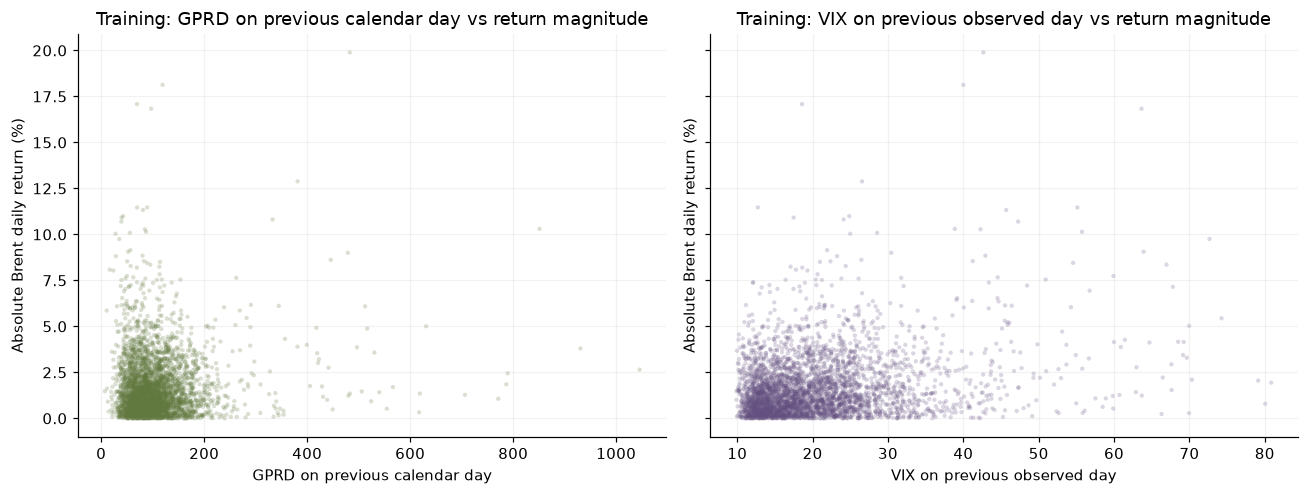

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), sharey=True)
for ax, col, label, color in [
    (axes[0], "gpr_lag1_calendar_day", "GPRD on previous calendar day", "#61783e"),
    (axes[1], "vix_lag1_observation", "VIX on previous observed day", "#655181"),
]:
    ax.scatter(cc_train[col], cc_train["abs_brent_return_pct"],
               s=8, alpha=.23, color=color, edgecolors="none")
    ax.set(xlabel=label, ylabel="Absolute Brent daily return (%)",
           title=f"Training: {label} vs return magnitude")
    ax.grid(alpha=.16)
fig.tight_layout()
fig.savefig(FIGURES / "02_predictor_scatter.png", bbox_inches="tight")
plt.show()

## 8. Consolidated test results and interpretation

The table collects **training-only** tests. Decisions use a prespecified 5% threshold. P-values shown as bounds or underflow are not exact zeros or exact tail probabilities. The ADF and KPSS tests concern the level behavior of returns; Ljung–Box and ARCH-LM concern serial dependence and conditional variance; Jarque–Bera concerns the marginal return distribution. None alone tests whether volatility has discrete regimes.

In [10]:
for _, row in stationarity.iterrows():
    summary_rows.append({"Test": f"{row['oil']} {row['test']}",
                         "Null hypothesis": row["null_hypothesis"],
                         "Test statistic": row["test_statistic"],
                         "P-value": row["p_display"],
                         "Interpretation": row["interpretation"]})
for _, row in ljung.iterrows():
    summary_rows.append({"Test": f"{row['oil']} Ljung-Box {row['series']}, lag {row['lags']}",
                         "Null hypothesis": f"no {row['series']} autocorrelation through lag {row['lags']}",
                         "Test statistic": row["test_statistic"],
                         "P-value": row["p_display"],
                         "Interpretation": row["interpretation"]})
for _, row in arch.iterrows():
    summary_rows.append({"Test": f"{row['oil']} ARCH-LM, lag {row['lags']}" +
                         (" (primary)" if row["primary_specification"] else ""),
                         "Null hypothesis": f"no ARCH effects through lag {row['lags']}",
                         "Test statistic": row["test_statistic"],
                         "P-value": row["p_display"],
                         "Interpretation": row["interpretation"]})
for _, row in jarque_bera.iterrows():
    summary_rows.append({"Test": f"{row['oil']} Jarque-Bera",
                         "Null hypothesis": "normal return distribution",
                         "Test statistic": row["test_statistic"],
                         "P-value": row["p_display"],
                         "Interpretation": row["interpretation"]})
test_summary = pd.DataFrame(summary_rows)
assert list(test_summary) == ["Test", "Null hypothesis", "Test statistic",
                              "P-value", "Interpretation"]
display(test_summary.round({"Test statistic": 4}))
test_summary.to_csv(TABLES / "02_test_summary.csv", index=False, float_format="%.10g")

def test_p(table, oil_name, **conditions):
    selected = table.loc[table["oil"].eq(oil_name)]
    for col, value in conditions.items():
        selected = selected.loc[selected[col].eq(value)]
    assert len(selected) == 1
    return float(selected["p_value"].iloc[0])

adf_stationary = all(test_p(stationarity, oil_name, test="ADF") < .05 for oil_name in oil)
kpss_stationary = all(test_p(stationarity, oil_name, test="KPSS") >= .05 for oil_name in oil)
sq_dependence = all(test_p(ljung, oil_name, series="squared return", lags=10) < .05
                    for oil_name in oil)
brent_signed_dep = test_p(ljung, "Brent", series="return", lags=10) < .05
wti_signed_dep = test_p(ljung, "WTI", series="return", lags=10) < .05
arch_effect = all(test_p(arch, oil_name, lags=10) < .05 for oil_name in oil)
non_normal = all(test_p(jarque_bera, oil_name) < .05 for oil_name in oil)
gpr_abs = associations.loc[(associations["predictor"] == "previous-calendar-day GPR") &
                            (associations["response"] == "absolute Brent return"),
                            "pearson_r"].iloc[0]
vix_abs = associations.loc[(associations["predictor"] == "previous-observation VIX") &
                            (associations["response"] == "absolute Brent return"),
                            "pearson_r"].iloc[0]
gpr_abs_rank = associations.loc[(associations["predictor"] == "previous-calendar-day GPR") &
                                 (associations["response"] == "absolute Brent return"),
                                 "spearman_rho"].iloc[0]
vix_abs_rank = associations.loc[(associations["predictor"] == "previous-observation VIX") &
                                 (associations["response"] == "absolute Brent return"),
                                 "spearman_rho"].iloc[0]
brent_train_sd = split_descriptive.loc[
    (split_descriptive["oil"] == "Brent") & (split_descriptive["period"] == "train"), "sd_pct"].iloc[0]
brent_validation_sd = split_descriptive.loc[
    (split_descriptive["oil"] == "Brent") & (split_descriptive["period"] == "validation"), "sd_pct"].iloc[0]
brent_test_sd = split_descriptive.loc[
    (split_descriptive["oil"] == "Brent") & (split_descriptive["period"] == "test"), "sd_pct"].iloc[0]
wti_train_sd = split_descriptive.loc[
    (split_descriptive["oil"] == "WTI") & (split_descriptive["period"] == "train"), "sd_pct"].iloc[0]
wti_validation_sd = split_descriptive.loc[
    (split_descriptive["oil"] == "WTI") & (split_descriptive["period"] == "validation"), "sd_pct"].iloc[0]
wti_test_sd = split_descriptive.loc[
    (split_descriptive["oil"] == "WTI") & (split_descriptive["period"] == "test"), "sd_pct"].iloc[0]
brent_2020_min = extreme_2020.loc[extreme_2020["oil"].eq("Brent"), "return_pct"].min()
wti_2020_max = extreme_2020.loc[extreme_2020["oil"].eq("WTI"), "return_pct"].max()
signed_sentence = (
    "Signed Brent returns do not reject the 10-lag no-autocorrelation null, while signed WTI returns do"
    if not brent_signed_dep and wti_signed_dep else
    "The signed-return Ljung-Box results should be read alongside the ACF magnitudes"
)

interpretation = f'''
### Findings from this processed-data snapshot

1. **Stationarity:** {"Both returns reject the ADF unit-root null and do not reject the KPSS level-stationarity null" if adf_stationary and kpss_stationary else "The ADF and KPSS outcomes are mixed; inspect the detailed stationarity table"}. This supports treating returns, rather than price levels, as the stationary modelling variables, subject to the tests' assumptions.
2. **Volatility clustering:** {"Both squared-return series reject the Ljung-Box no-autocorrelation null at 10 lags" if sq_dependence else "Squared-return dependence differs across the two series; see the Ljung-Box table"}. This concerns return magnitude. {signed_sentence}; the ACF magnitudes remain small.
3. **ARCH effects:** {"Both 10-lag ARCH-LM tests reject no ARCH effects" if arch_effect else "The 10-lag ARCH-LM results differ across series; see the detailed table"}. Conditional variance is therefore a relevant feature to model.
4. **Distribution:** {"Both training return series reject Gaussian normality in the Jarque-Bera test" if non_normal else "Normality results differ across series; see the detailed table"}. Q-Q tail departures and excess kurtosis should be considered when later using Gaussian likelihoods. The 2020 extremes include a **{brent_2020_min:.2f}%** Brent return and **+{wti_2020_max:.2f}%** WTI return; these test-period observations were not removed.
5. **GPR and VIX:** In the training complete-case sample, Pearson correlations of prior-reference-date GPR and VIX with absolute Brent returns are **{gpr_abs:.3f}** and **{vix_abs:.3f}**; Spearman correlations are **{gpr_abs_rank:.3f}** and **{vix_abs_rank:.3f}**. The VIX association is larger here, while the GPR rank association is weak. These are associations with a realized return-magnitude proxy, not causal effects or validated predictive gains; the GPR vintage is revised.
6. **Later model comparison:** Brent return standard deviations are **{brent_train_sd:.2f}% / {brent_validation_sd:.2f}% / {brent_test_sd:.2f}%** in training / validation / test; WTI values are **{wti_train_sd:.2f}% / {wti_validation_sd:.2f}% / {wti_test_sd:.2f}%** (descriptive only). The diagnostics motivate a comparison of constant-variance, GARCH, and Markov-switching specifications. **They do not establish that discrete volatility regimes exist.**
'''
display(Markdown(interpretation))
print("Notebook 02 tables:", len(list(TABLES.glob("02_*.csv"))),
      "| figures:", len(list(FIGURES.glob("02_*.png"))))

,Test,Null hypothesis,Test statistic,P-value,Interpretation
0,Brent ADF,unit root,-60.0882,<1e-300 (underflow),Reject unit root
1,Brent KPSS,level stationarity,0.3161,>=0.10 (table bound),Do not reject level stationarity
2,WTI ADF,unit root,-16.2952,3.31e-29,Reject unit root
3,WTI KPSS,level stationarity,0.2706,>=0.10 (table bound),Do not reject level stationarity
4,"Brent Ljung-Box return, lag 5",no return autocorrelation through lag 5,3.1138,0.682,Do not reject no autocorrelation
5,"Brent Ljung-Box return, lag 10",no return autocorrelation through lag 10,12.5210,0.252,Do not reject no autocorrelation
6,"Brent Ljung-Box return, lag 20",no return autocorrelation through lag 20,26.2919,0.156,Do not reject no autocorrelation
7,"Brent Ljung-Box squared return, lag 5",no squared return autocorrelation through lag 5,224.2622,1.81e-46,Reject no autocorrelation
8,"Brent Ljung-Box squared return, lag 10",no squared return autocorrelation through lag 10,323.9484,1.33e-63,Reject no autocorrelation
9,"Brent Ljung-Box squared return, lag 20",no squared return autocorrelation through lag 20,755.6288,3.66e-147,Reject no autocorrelation



### Findings from this processed-data snapshot

1. **Stationarity:** Both returns reject the ADF unit-root null and do not reject the KPSS level-stationarity null. This supports treating returns, rather than price levels, as the stationary modelling variables, subject to the tests' assumptions.
2. **Volatility clustering:** Both squared-return series reject the Ljung-Box no-autocorrelation null at 10 lags. This concerns return magnitude. Signed Brent returns do not reject the 10-lag no-autocorrelation null, while signed WTI returns do; the ACF magnitudes remain small.
3. **ARCH effects:** Both 10-lag ARCH-LM tests reject no ARCH effects. Conditional variance is therefore a relevant feature to model.
4. **Distribution:** Both training return series reject Gaussian normality in the Jarque-Bera test. Q-Q tail departures and excess kurtosis should be considered when later using Gaussian likelihoods. The 2020 extremes include a **-64.37%** Brent return and **+42.58%** WTI return; these test-period observations were not removed.
5. **GPR and VIX:** In the training complete-case sample, Pearson correlations of prior-reference-date GPR and VIX with absolute Brent returns are **0.076** and **0.245**; Spearman correlations are **0.022** and **0.179**. The VIX association is larger here, while the GPR rank association is weak. These are associations with a realized return-magnitude proxy, not causal effects or validated predictive gains; the GPR vintage is revised.
6. **Later model comparison:** Brent return standard deviations are **2.34% / 2.17% / 3.68%** in training / validation / test; WTI values are **2.59% / 2.27% / 3.58%** (descriptive only). The diagnostics motivate a comparison of constant-variance, GARCH, and Markov-switching specifications. **They do not establish that discrete volatility regimes exist.**


Notebook 02 tables: 11 | figures: 3
